# Irmak — LightGBM
Predict `is_canceled` using the existing preprocessing and unchanged partitions.

| Experiment | Train | Validation | Test | Selection |
|---|---|---|---|---|
| Random | 70% | 15% | 15% | Train-only stratified 5-fold CV AP, then 1-SE simplicity rule |
| Temporal | All 2015–2016 | None | All 2017 | All 15 predefined settings; no winner selection |

Run cells in order. `lightgbm_1` is the baseline; the remaining 14 settings are sampled with seed 42. Matching model names use identical settings in both experiments. All encoders fit inside the training fold/pipeline.

The selected random pipeline's threshold is tuned on validation F1. Random test is evaluated once after selection. Temporal test results are descriptive and must not be used to choose settings. `pr_auc` means **average precision**.

Full execution performs 75 CV fits, 15 random fits and 15 temporal fits. Results are shown below and saved only when the final output cells run. Save the executed notebook to retain outputs.

## 1. Imports and execution settings

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import display

def find_project_root(start_directory: Path) -> Path:
    for directory in (start_directory, *start_directory.parents):
        if (directory / "src" / "data_split.py").is_file():
            return directory
    raise FileNotFoundError("Open the notebook inside hotel-cancellation.")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_split import main as create_data_splits
from src.irmak_lightgbm import (
    ExperimentConfig, sample_model_parameters, parameter_summary, summarize_splits,
    fit_random_experiment, evaluate_random_test, run_temporal_experiment,
    combine_results, random_overfit_summary, save_numbered_results,
    export_comparison_plots,
)

config = ExperimentConfig(random_seed=42, model_count=15, cv_folds=5, model_jobs=2)
results_directory = PROJECT_ROOT / "results" / "irmak_lightgbm"
pd.set_option("display.max_columns", None)
print(config)
print("Output directory:", results_directory)

ExperimentConfig(random_seed=42, model_count=15, cv_folds=5, model_jobs=2, thresholds=(np.float64(0.2), np.float64(0.225), np.float64(0.25), np.float64(0.275), np.float64(0.3), np.float64(0.325), np.float64(0.35), np.float64(0.375), np.float64(0.4), np.float64(0.425), np.float64(0.45), np.float64(0.475), np.float64(0.5), np.float64(0.525), np.float64(0.55), np.float64(0.575), np.float64(0.6), np.float64(0.625), np.float64(0.65), np.float64(0.675), np.float64(0.7), np.float64(0.725), np.float64(0.75), np.float64(0.775), np.float64(0.8)))
Output directory: C:\Users\lenovo\Documents\CODING\cmpe481_term_project\hotel-cancellation\results\irmak_lightgbm


In [2]:
# Confirm the notebook uses the intended interpreter and can import LightGBM.
import lightgbm
print("Python executable:", sys.executable)
print("LightGBM version:", lightgbm.__version__)

Python executable: c:\Users\lenovo\AppData\Local\Programs\Python\Python312\python.exe
LightGBM version: 4.7.0


## 2. Predefine and display all model settings
`lightgbm_1` is a baseline configuration, not a known best model. The other settings are sampled without replacement. Depth and leaf count satisfy `num_leaves <= 2**max_depth`. Sampling occurs before any held-out evaluation. Classifier settings shared by all models: binary objective, seed 42, gain importance, deterministic CPU training; one-hot encoding matches the Random Forest representation.

In [3]:
model_parameters = sample_model_parameters(config)
with pd.option_context("display.max_rows", None):
    display(parameter_summary(model_parameters, config))

,experiment,model,learning_rate,n_estimators,num_leaves,max_depth,min_child_samples,colsample_bytree,reg_lambda,random_state,objective
0,random,lightgbm_1,0.10,200,31,7,20,1.0,0.0,42,binary
1,random,lightgbm_2,0.05,500,31,7,20,1.0,1.0,42,binary
2,random,lightgbm_3,0.03,500,15,7,100,0.8,1.0,42,binary
3,random,lightgbm_4,0.03,800,63,7,50,1.0,1.0,42,binary
4,random,lightgbm_5,0.10,500,31,10,20,0.8,0.0,42,binary
5,random,lightgbm_6,0.03,800,63,10,100,0.8,0.0,42,binary
6,random,lightgbm_7,0.03,500,31,10,50,0.8,5.0,42,binary
7,random,lightgbm_8,0.10,200,15,7,100,1.0,1.0,42,binary
8,random,lightgbm_9,0.10,800,31,7,20,1.0,1.0,42,binary
9,random,lightgbm_10,0.10,800,15,10,100,0.8,5.0,42,binary


## 3. Load the existing splits
Preprocessing removes outcome columns and adds the existing derived features. `split_features_target` excludes both `is_canceled` and `arrival_date_year` from inputs. No new temporal validation set or split files are created. Overlap between random and temporal experiments is expected; overlap within one experiment is rejected.

In [4]:
data_splits = create_data_splits()
display(summarize_splits(data_splits))

,experiment,partition,rows,canceled_rate
0,random,train,59576,0.276135
1,random,validation,12766,0.276124
2,random,test,12767,0.276102
3,temporal,train,53998,0.250824
4,temporal,test,31111,0.320048


## 4. Select the random model and tune its threshold
Model ranking uses mean training-CV AP, with ROC-AUC as a tie-breaker. Eligible settings lie within one standard error of the best mean AP. Simplicity order: fewer leaves, shallower depth, larger `min_child_samples`, fewer trees; remaining ties use CV AP, ROC-AUC and model name.

Selection is frozen before collecting train/validation diagnostics. The selected train-fitted model's threshold maximizes validation F1 over 0.20–0.80 in steps of 0.025. Ties favor proximity to 0.5, then the lower threshold. This function receives no test data. `fit_seconds` measures a full train fit; `cv_fit_seconds_mean` measures mean fold fit time.

In [5]:
random_selection = fit_random_experiment(
    data_splits["random"]["train"],
    data_splits["random"]["validation"],
    model_parameters,
    config,
)
display(random_selection.cv_comparison)
display(random_selection.threshold_trials)
print("Selected model:", random_selection.selected_model_name)
print("Selected threshold:", random_selection.selected_threshold)
display(pd.DataFrame(random_selection.evaluation_rows))

lightgbm_1: train CV AP=0.7971
lightgbm_2: train CV AP=0.7980
lightgbm_3: train CV AP=0.7891
lightgbm_4: train CV AP=0.7991
lightgbm_5: train CV AP=0.8038
lightgbm_6: train CV AP=0.8048
lightgbm_7: train CV AP=0.7976
lightgbm_8: train CV AP=0.7923
lightgbm_9: train CV AP=0.8032
lightgbm_10: train CV AP=0.8015
lightgbm_11: train CV AP=0.7984
lightgbm_12: train CV AP=0.7986
lightgbm_13: train CV AP=0.8011
lightgbm_14: train CV AP=0.8025
lightgbm_15: train CV AP=0.7992
lightgbm_1 (random_selection_train): F1=0.733, ROC-AUC=0.929
lightgbm_1 (random_validation): F1=0.701, ROC-AUC=0.910
lightgbm_2 (random_selection_train): F1=0.735, ROC-AUC=0.929
lightgbm_2 (random_validation): F1=0.704, ROC-AUC=0.910
lightgbm_3 (random_selection_train): F1=0.706, ROC-AUC=0.914
lightgbm_3 (random_validation): F1=0.696, ROC-AUC=0.907
lightgbm_4 (random_selection_train): F1=0.742, ROC-AUC=0.933
lightgbm_4 (random_validation): F1=0.707, ROC-AUC=0.911
lightgbm_5 (random_selection_train): F1=0.795, ROC-AUC=0.956


,model,learning_rate,n_estimators,num_leaves,max_depth,min_child_samples,colsample_bytree,reg_lambda,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_fit_seconds_mean,cv_pr_auc_se,one_se_eligible,selected_by_cv
0,lightgbm_6,0.03,800,63,10,100,0.8,0.0,0.804766,0.003589,0.914403,4.391368,0.001605,True,False
1,lightgbm_5,0.10,500,31,10,20,0.8,0.0,0.803758,0.003046,0.913492,1.960990,0.001362,True,False
2,lightgbm_9,0.10,800,31,7,20,1.0,1.0,0.803230,0.002587,0.912850,3.060797,0.001157,True,True
3,lightgbm_14,0.10,500,63,7,100,0.8,1.0,0.802463,0.004114,0.913155,2.087635,0.001840,False,False
4,lightgbm_10,0.10,800,15,10,100,0.8,5.0,0.801456,0.002893,0.912440,2.488879,0.001294,False,False
5,lightgbm_13,0.10,800,31,10,100,1.0,0.0,0.801114,0.002926,0.912357,3.009723,0.001309,False,False
6,lightgbm_15,0.10,500,15,7,20,1.0,0.0,0.799176,0.002391,0.911650,1.701904,0.001069,False,False
7,lightgbm_4,0.03,800,63,7,50,1.0,1.0,0.799108,0.003094,0.911606,3.226414,0.001384,False,False
8,lightgbm_12,0.03,800,63,7,20,1.0,1.0,0.798622,0.002721,0.910918,3.390981,0.001217,False,False
9,lightgbm_11,0.10,500,15,5,100,0.8,1.0,0.798428,0.002522,0.911122,1.753626,0.001128,False,False


,threshold,f1,distance_from_half
0,0.350,0.729390,0.150
1,0.375,0.728769,0.125
2,0.400,0.728288,0.100
3,0.425,0.727980,0.075
4,0.325,0.726445,0.175
5,0.450,0.725669,0.050
6,0.300,0.722708,0.200
7,0.475,0.720697,0.025
8,0.275,0.720230,0.225
9,0.250,0.714919,0.250


Selected model: lightgbm_9
Selected threshold: 0.35


,model,split,f1,roc_auc,precision,recall,experiment,partition,learning_rate,n_estimators,num_leaves,max_depth,min_child_samples,colsample_bytree,reg_lambda,random_state,threshold,training_rows,evaluated_rows,fit_seconds,pr_auc,accuracy,tn,fp,fn,tp,cv_pr_auc_mean,cv_pr_auc_std,cv_pr_auc_se,cv_roc_auc_mean,cv_fit_seconds_mean,one_se_eligible,selected_by_cv
0,lightgbm_1,random_selection_train,0.733476,0.928950,0.783597,0.689381,random,selection_train,0.10,200,31,7,20,1.0,0.0,42,0.50,59576,59576,1.457220,0.835947,0.861656,39993,3132,5110,11341,0.797130,0.002907,0.001300,0.910360,1.537917,False,False
1,lightgbm_1,random_validation,0.701220,0.909575,0.747751,0.660142,random,validation,0.10,200,31,7,20,1.0,0.0,42,0.50,59576,12766,1.457220,0.797581,0.844666,8456,785,1198,2327,0.797130,0.002907,0.001300,0.910360,1.537917,False,False
2,lightgbm_2,random_selection_train,0.734599,0.929328,0.783417,0.691508,random,selection_train,0.05,500,31,7,20,1.0,1.0,42,0.50,59576,59576,2.659285,0.837276,0.862025,39980,3145,5075,11376,0.798040,0.003074,0.001375,0.910831,2.235192,False,False
3,lightgbm_2,random_validation,0.704221,0.910270,0.748404,0.664965,random,validation,0.05,500,31,7,20,1.0,1.0,42,0.50,59576,12766,2.659285,0.798259,0.845762,8453,788,1181,2344,0.798040,0.003074,0.001375,0.910831,2.235192,False,False
4,lightgbm_3,random_selection_train,0.705756,0.913925,0.759832,0.658866,random,selection_train,0.03,500,15,7,100,0.8,1.0,42,0.50,59576,59576,2.331169,0.804264,0.848295,39699,3426,5612,10839,0.789128,0.002671,0.001195,0.906910,1.957329,False,False
5,lightgbm_3,random_validation,0.696139,0.907136,0.746429,0.652199,random,validation,0.03,500,15,7,100,0.8,1.0,42,0.50,59576,12766,2.331169,0.790298,0.842786,8460,781,1226,2299,0.789128,0.002671,0.001195,0.906910,1.957329,False,False
6,lightgbm_4,random_selection_train,0.742156,0.933327,0.789459,0.700201,random,selection_train,0.03,800,63,7,50,1.0,1.0,42,0.50,59576,59576,4.112465,0.846086,0.865651,40053,3072,4932,11519,0.799108,0.003094,0.001384,0.911606,3.226414,False,False
7,lightgbm_4,random_validation,0.707401,0.910524,0.751276,0.668369,random,validation,0.03,800,63,7,50,1.0,1.0,42,0.50,59576,12766,4.112465,0.798473,0.847329,8461,780,1169,2356,0.799108,0.003094,0.001384,0.911606,3.226414,False,False
8,lightgbm_5,random_selection_train,0.795186,0.955819,0.832458,0.761109,random,selection_train,0.10,500,31,10,20,0.8,0.0,42,0.50,59576,59576,2.641329,0.894223,0.891735,40605,2520,3930,12521,0.803758,0.003046,0.001362,0.913492,1.960990,True,False
9,lightgbm_5,random_validation,0.715115,0.913192,0.752665,0.681135,random,validation,0.10,500,31,10,20,0.8,0.0,42,0.50,59576,12766,2.641329,0.804509,0.850149,8452,789,1124,2401,0.803758,0.003046,0.001362,0.913492,1.960990,True,False


## 5. Evaluate the frozen random model
The same train-fitted pipeline and validation-selected threshold score train and held-out test. This call rejects a repeated test evaluation on the same selection object. To rerun the full experiment, restart from the setup cell.

In [6]:
random_final_rows = evaluate_random_test(
    random_selection,
    data_splits["random"]["train"],
    data_splits["random"]["test"],
    config,
)
display(pd.DataFrame(random_final_rows))
display(random_selection.feature_importance.head(15).to_frame())

lightgbm_9 (random_final_train): F1=0.806, ROC-AUC=0.956
lightgbm_9 (random_test): F1=0.729, ROC-AUC=0.913


,model,split,f1,roc_auc,precision,recall,experiment,partition,reg_lambda,num_leaves,n_estimators,min_child_samples,max_depth,learning_rate,colsample_bytree,random_state,threshold,training_rows,evaluated_rows,fit_seconds,pr_auc,accuracy,tn,fp,fn,tp,cv_pr_auc_mean,cv_pr_auc_std,cv_pr_auc_se,cv_roc_auc_mean,cv_fit_seconds_mean,one_se_eligible,selected_by_cv
0,lightgbm_9,random_final_train,0.806234,0.955944,0.742403,0.882074,random,final_train,1.0,31,800,20,7,0.1,1.0,42,0.35,59576,59576,3.556625,0.896001,0.882923,38090,5035,1940,14511,0.80323,0.002587,0.001157,0.91285,3.060797,True,True
1,lightgbm_9,random_test,0.729473,0.913492,0.673798,0.795177,random,test,1.0,31,800,20,7,0.1,1.0,42,0.35,59576,12767,3.556625,0.804904,0.837158,7885,1357,722,2803,0.80323,0.002587,0.001157,0.91285,3.060797,True,True


,gain_importance_share
country,0.160030
lead_time,0.150821
agent,0.138898
total_of_special_requests,0.089554
required_car_parking_spaces,0.084235
market_segment,0.070907
adr,0.051406
customer_type,0.032206
arrival_date_month,0.024719
reserved_room_type,0.024036


## 6. Run all predefined temporal configurations
Train each setting on all 2015–2016 records and report 2017 at threshold 0.5. No validation, CV selection, threshold tuning, early stopping, or test-based winner is introduced. Feature importance comes from training split gain, normalized and aggregated to original columns; it does not measure causal influence.

In [7]:
temporal_rows, temporal_feature_importances = run_temporal_experiment(
    data_splits["temporal"]["train"],
    data_splits["temporal"]["test"],
    model_parameters,
    config,
)
display(pd.DataFrame(temporal_rows))
display(temporal_feature_importances)

lightgbm_1 (temporal_train): F1=0.749, ROC-AUC=0.943
lightgbm_1 (temporal_test): F1=0.604, ROC-AUC=0.863
lightgbm_2 (temporal_train): F1=0.751, ROC-AUC=0.942
lightgbm_2 (temporal_test): F1=0.605, ROC-AUC=0.863
lightgbm_3 (temporal_train): F1=0.718, ROC-AUC=0.928
lightgbm_3 (temporal_test): F1=0.601, ROC-AUC=0.862
lightgbm_4 (temporal_train): F1=0.753, ROC-AUC=0.945
lightgbm_4 (temporal_test): F1=0.606, ROC-AUC=0.861
lightgbm_5 (temporal_train): F1=0.816, ROC-AUC=0.968
lightgbm_5 (temporal_test): F1=0.606, ROC-AUC=0.854
lightgbm_6 (temporal_train): F1=0.796, ROC-AUC=0.961
lightgbm_6 (temporal_test): F1=0.607, ROC-AUC=0.855
lightgbm_7 (temporal_train): F1=0.741, ROC-AUC=0.938
lightgbm_7 (temporal_test): F1=0.602, ROC-AUC=0.862
lightgbm_8 (temporal_train): F1=0.723, ROC-AUC=0.931
lightgbm_8 (temporal_test): F1=0.605, ROC-AUC=0.861
lightgbm_9 (temporal_train): F1=0.815, ROC-AUC=0.967
lightgbm_9 (temporal_test): F1=0.604, ROC-AUC=0.854
lightgbm_10 (temporal_train): F1=0.770, ROC-AUC=0.951
l

,model,split,f1,roc_auc,precision,recall,experiment,partition,learning_rate,n_estimators,num_leaves,max_depth,min_child_samples,colsample_bytree,reg_lambda,random_state,threshold,training_rows,evaluated_rows,fit_seconds,pr_auc,accuracy,tn,fp,fn,tp
0,lightgbm_1,temporal_train,0.748798,0.942562,0.810527,0.695806,temporal,train,0.10,200,31,7,20,1.0,0.0,42,0.5,53998,53998,1.281436,0.857032,0.882903,38251,2203,4120,9424
1,lightgbm_1,temporal_test,0.603812,0.863022,0.738455,0.510696,temporal,test,0.10,200,31,7,20,1.0,0.0,42,0.5,53998,31111,1.281436,0.724031,0.785510,19353,1801,4872,5085
2,lightgbm_2,temporal_train,0.750743,0.942266,0.810388,0.699276,temporal,train,0.05,500,31,7,20,1.0,1.0,42,0.5,53998,53998,2.629142,0.856560,0.883533,38238,2216,4073,9471
3,lightgbm_2,temporal_test,0.605212,0.862679,0.739913,0.512002,temporal,test,0.05,500,31,7,20,1.0,1.0,42,0.5,53998,31111,2.629142,0.725107,0.786217,19362,1792,4859,5098
4,lightgbm_3,temporal_train,0.717570,0.927728,0.787302,0.659185,temporal,train,0.03,500,15,7,100,0.8,1.0,42,0.5,53998,53998,2.287811,0.825433,0.869847,38042,2412,4616,8928
5,lightgbm_3,temporal_test,0.600597,0.862228,0.739821,0.505474,temporal,test,0.03,500,15,7,100,0.8,1.0,42,0.5,53998,31111,2.287811,0.721310,0.784835,19384,1770,4924,5033
6,lightgbm_4,temporal_train,0.753141,0.944827,0.812901,0.701565,temporal,train,0.03,800,63,7,50,1.0,1.0,42,0.5,53998,53998,4.090532,0.862012,0.884644,38267,2187,4042,9502
7,lightgbm_4,temporal_test,0.606215,0.860704,0.738109,0.514312,temporal,test,0.03,800,63,7,50,1.0,1.0,42,0.5,53998,31111,4.090532,0.722661,0.786153,19337,1817,4836,5121
8,lightgbm_5,temporal_train,0.815672,0.967767,0.863101,0.773184,temporal,train,0.10,500,31,10,20,0.8,0.0,42,0.5,53998,53998,2.387511,0.914908,0.912349,38793,1661,3072,10472
9,lightgbm_5,temporal_test,0.605968,0.854189,0.727887,0.519032,temporal,test,0.10,500,31,10,20,0.8,0.0,42,0.5,53998,31111,2.387511,0.718287,0.783967,19222,1932,4789,5168


,adr,adults,agent,arrival_date_month,arrival_weekday,assigned_room_type,babies,booking_changes,children,company,country,customer_type,days_in_waiting_list,deposit_type,distribution_channel,hotel,is_repeated_guest,lead_time,market_segment,meal,previous_bookings_not_canceled,previous_cancellations,required_car_parking_spaces,reserved_room_type,stays_in_week_nights,stays_in_weekend_nights,total_guests,total_nights,total_of_special_requests
model,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
lightgbm_1,0.029734,0.001886,0.212720,0.020038,0.004516,0.015308,0.000402,0.016343,0.002125,0.002770,0.139721,0.036625,0.000887,0.021750,0.006651,0.002679,0.002116,0.119962,0.036592,0.005335,0.016521,0.038962,0.098663,0.024802,0.004501,0.003502,0.002044,0.010383,0.122460
lightgbm_2,0.029359,0.001614,0.210167,0.019177,0.004154,0.015248,0.000358,0.016123,0.002266,0.002957,0.143898,0.037440,0.001082,0.021407,0.006584,0.002576,0.001960,0.120967,0.037123,0.004567,0.015580,0.038262,0.098758,0.025277,0.004237,0.003979,0.001944,0.010240,0.122695
lightgbm_3,0.020365,0.000795,0.186559,0.014667,0.001467,0.016645,0.000315,0.016518,0.001939,0.000364,0.128441,0.041671,0.000843,0.034821,0.009071,0.003457,0.001121,0.103827,0.070752,0.003390,0.017591,0.047782,0.104302,0.022073,0.005531,0.001223,0.000999,0.017880,0.125592
lightgbm_4,0.033696,0.001703,0.210185,0.019839,0.004701,0.014900,0.000391,0.016360,0.002228,0.001474,0.139524,0.034837,0.000922,0.019590,0.005425,0.002675,0.002507,0.125847,0.037874,0.005048,0.016492,0.035019,0.096517,0.026353,0.005533,0.004673,0.001828,0.011504,0.122356
lightgbm_5,0.054767,0.003112,0.160707,0.030630,0.012559,0.024214,0.000616,0.017029,0.002135,0.002885,0.133015,0.038666,0.001120,0.024744,0.009343,0.008336,0.002446,0.120314,0.052579,0.008060,0.013830,0.033819,0.076040,0.020771,0.012719,0.006119,0.004496,0.023484,0.101448
lightgbm_6,0.055016,0.002991,0.153907,0.029001,0.009469,0.021205,0.000419,0.016030,0.002177,0.000851,0.117919,0.036296,0.000767,0.028912,0.011869,0.007363,0.001987,0.118729,0.064097,0.007486,0.013242,0.037583,0.081135,0.024435,0.014279,0.007195,0.004504,0.024193,0.106946
lightgbm_7,0.032231,0.001422,0.191024,0.021300,0.003236,0.020872,0.000290,0.016246,0.001785,0.001227,0.126514,0.042068,0.000866,0.032871,0.007755,0.005220,0.001590,0.112148,0.060107,0.005209,0.016714,0.044752,0.095858,0.020716,0.005135,0.003268,0.003151,0.016434,0.109991
lightgbm_8,0.020765,0.001000,0.206137,0.015430,0.002336,0.013430,0.000338,0.016207,0.001754,0.000333,0.151078,0.040567,0.000877,0.022458,0.006899,0.002829,0.001216,0.114200,0.043176,0.003780,0.017984,0.040967,0.106776,0.026717,0.004300,0.001955,0.001780,0.009301,0.125409
lightgbm_9,0.052142,0.002950,0.188655,0.029497,0.011933,0.017951,0.000433,0.016569,0.002849,0.002863,0.134114,0.033582,0.001166,0.018542,0.005684,0.003713,0.001800,0.133341,0.034890,0.007054,0.014505,0.032716,0.083717,0.024712,0.010072,0.006463,0.003155,0.015395,0.109537


## 7. Combined results and one numbered CSV
All parameters, partitions, thresholds, training times and scores appear together. CV metadata applies only to random settings; empty temporal CV fields mean not applicable. Existing CSVs are preserved. Repeating this saving cell creates another numbered CSV containing the same in-memory results.

In [8]:
model_results = combine_results(
    random_selection.evaluation_rows, random_final_rows, temporal_rows,
)
with pd.option_context("display.max_rows", None):
    display(model_results)
results_path = save_numbered_results(model_results, results_directory)
print("Saved:", results_path)

,model,split,f1,roc_auc,precision,recall,experiment,partition,learning_rate,n_estimators,num_leaves,max_depth,min_child_samples,colsample_bytree,reg_lambda,random_state,threshold,training_rows,evaluated_rows,fit_seconds,pr_auc,accuracy,tn,fp,fn,tp,cv_pr_auc_mean,cv_pr_auc_std,cv_pr_auc_se,cv_roc_auc_mean,cv_fit_seconds_mean,one_se_eligible,selected_by_cv
0,lightgbm_9,random_final_train,0.806234,0.955944,0.742403,0.882074,random,final_train,0.10,800,31,7,20,1.0,1.0,42,0.35,59576,59576,3.556625,0.896001,0.882923,38090,5035,1940,14511,0.803230,0.002587,0.001157,0.912850,3.060797,True,True
1,lightgbm_13,random_selection_train,0.824206,0.965865,0.853506,0.796851,random,selection_train,0.10,800,31,10,100,1.0,0.0,42,0.50,59576,59576,3.595252,0.918563,0.906137,40875,2250,3342,13109,0.801114,0.002926,0.001309,0.912357,3.009723,False,False
2,lightgbm_9,random_selection_train,0.798017,0.955944,0.836119,0.763236,random,selection_train,0.10,800,31,7,20,1.0,1.0,42,0.50,59576,59576,3.556625,0.896001,0.893313,40664,2461,3895,12556,0.803230,0.002587,0.001157,0.912850,3.060797,True,True
3,lightgbm_5,random_selection_train,0.795186,0.955819,0.832458,0.761109,random,selection_train,0.10,500,31,10,20,0.8,0.0,42,0.50,59576,59576,2.641329,0.894223,0.891735,40605,2520,3930,12521,0.803758,0.003046,0.001362,0.913492,1.960990,True,False
4,lightgbm_14,random_selection_train,0.781994,0.949187,0.817796,0.749195,random,selection_train,0.10,500,63,7,100,0.8,1.0,42,0.50,59576,59576,2.444614,0.881521,0.884652,40379,2746,4126,12325,0.802463,0.004114,0.001840,0.913155,2.087635,False,False
5,lightgbm_6,random_selection_train,0.774006,0.947344,0.813547,0.738131,random,selection_train,0.03,800,63,10,100,0.8,0.0,42,0.50,59576,59576,4.694911,0.877091,0.880976,40342,2783,4308,12143,0.804766,0.003589,0.001605,0.914403,4.391368,True,False
6,lightgbm_10,random_selection_train,0.757451,0.938312,0.794475,0.723725,random,selection_train,0.10,800,15,10,100,0.8,5.0,42,0.50,59576,59576,2.996530,0.858533,0.872012,40045,3080,4545,11906,0.801456,0.002893,0.001294,0.912440,2.488879,False,False
7,lightgbm_15,random_selection_train,0.746767,0.933758,0.793099,0.705550,random,selection_train,0.10,500,15,7,20,1.0,0.0,42,0.50,59576,59576,2.040579,0.846330,0.867866,40097,3028,4844,11607,0.799176,0.002391,0.001069,0.911650,1.701904,False,False
8,lightgbm_4,random_selection_train,0.742156,0.933327,0.789459,0.700201,random,selection_train,0.03,800,63,7,50,1.0,1.0,42,0.50,59576,59576,4.112465,0.846086,0.865651,40053,3072,4932,11519,0.799108,0.003094,0.001384,0.911606,3.226414,False,False
9,lightgbm_12,random_selection_train,0.737498,0.930528,0.786422,0.694304,random,selection_train,0.03,800,63,7,20,1.0,1.0,42,0.50,59576,59576,3.828249,0.839006,0.863519,40023,3102,5029,11422,0.798622,0.002721,0.001217,0.910918,3.390981,False,False


Saved: C:\Users\lenovo\Documents\CODING\cmpe481_term_project\hotel-cancellation\results\irmak_lightgbm\model_results_1.csv


## 8. Random train–validation diagnostic
Compare each random model at the same fixed threshold 0.5. A train-minus-validation F1 gap of at least 0.05 is a configurable screening flag, not proof of overfitting. Temporal has no validation set, so this diagnostic does not apply to it.

In [9]:
overfit_summary = random_overfit_summary(model_results, f1_gap=0.05)
display(overfit_summary)

,model,train_f1,validation_f1,f1_gap,may_be_overfit
0,lightgbm_13,0.824206,0.719953,0.104254,True
1,lightgbm_9,0.798017,0.714732,0.083285,True
2,lightgbm_5,0.795186,0.715115,0.080071,True
3,lightgbm_14,0.781994,0.712712,0.069281,True
4,lightgbm_6,0.774006,0.711104,0.062902,True
5,lightgbm_10,0.757451,0.714986,0.042466,False
6,lightgbm_15,0.746767,0.704327,0.042440,False
7,lightgbm_4,0.742156,0.707401,0.034754,False
8,lightgbm_1,0.733476,0.701220,0.032255,False
9,lightgbm_12,0.737498,0.705282,0.032216,False


## 9. Display and export comparison figures
Separate AP charts show random validation and temporal test. Sorting is descriptive; random model selection remains the earlier training-CV decision. The selected random model's feature importance chart uses training gains only. PNG filenames share the combined CSV run number.

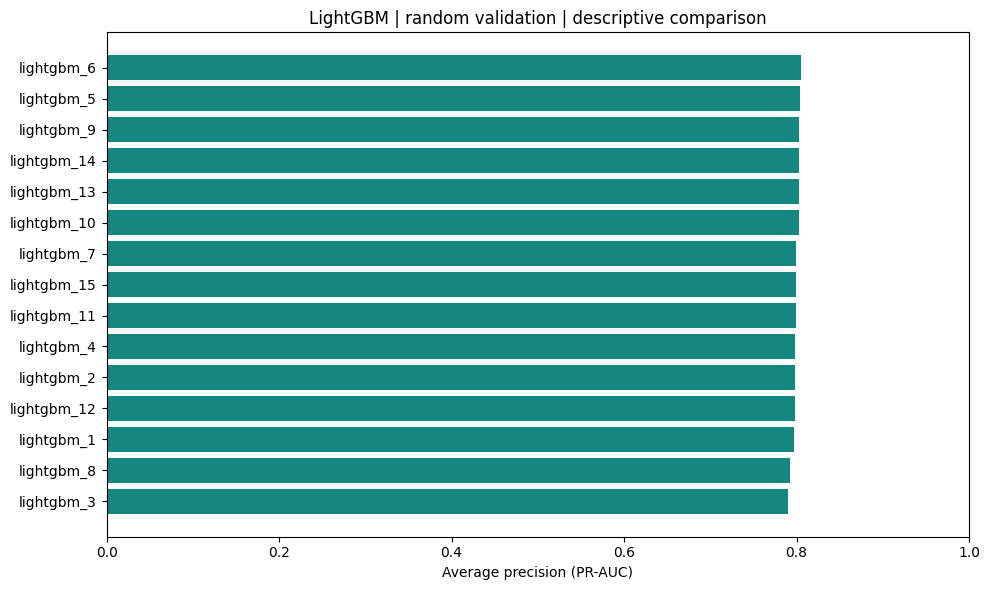

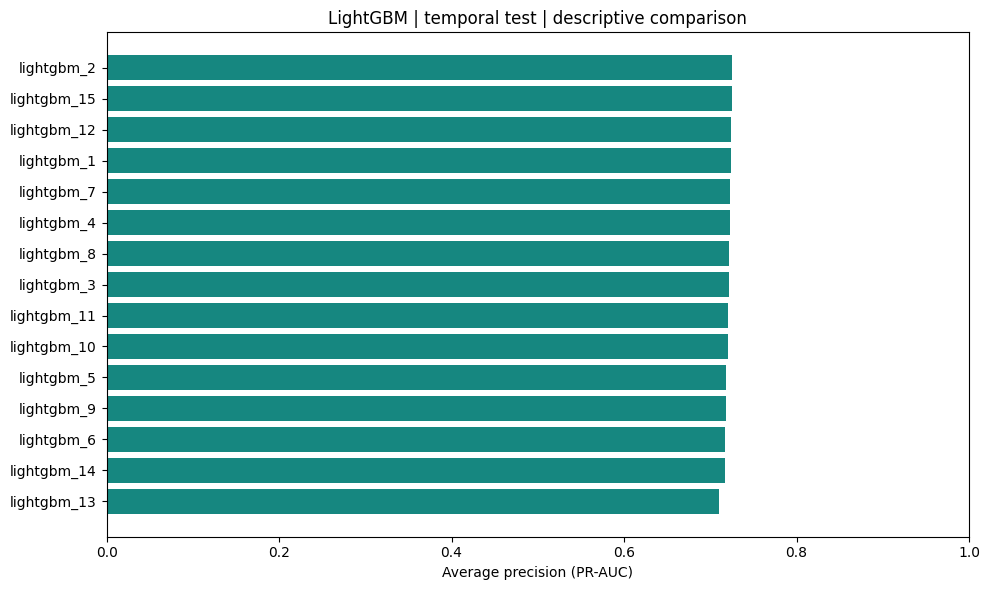

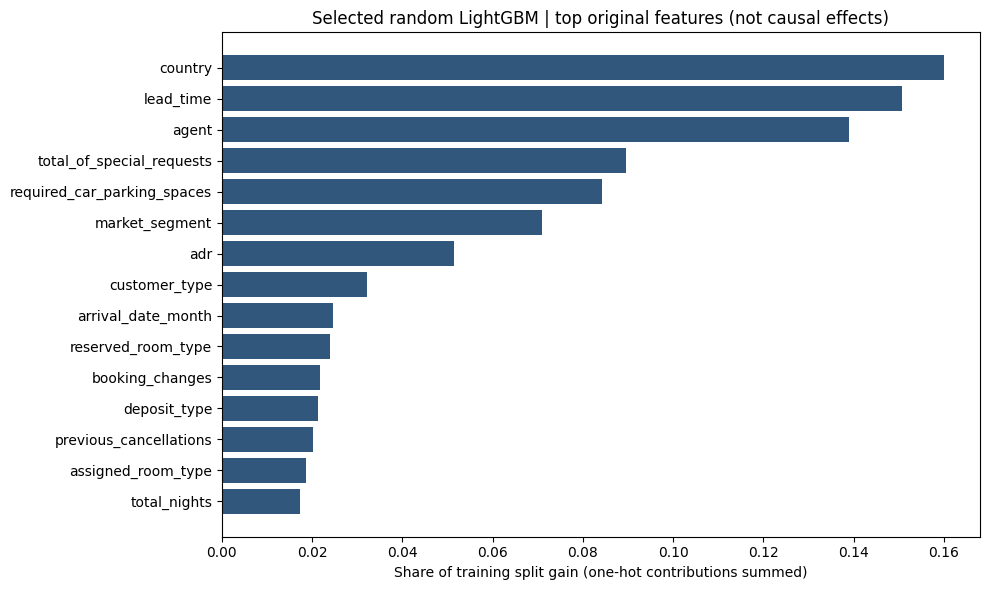

random_validation_ap_model_results_1.png
temporal_test_ap_model_results_1.png
random_feature_importance_model_results_1.png


In [10]:
plot_paths = export_comparison_plots(
    model_results, random_selection.feature_importance, results_path,
)
for plot_path in plot_paths:
    print(plot_path.name)